# SANPO-Synthetic validation split (official train split, chest + head)

**Purpose:** a validation set of synthetic walks to watch the synthetic pretraining stages (experiments 6 and 7) and to
choose their checkpoint. The final models are still chosen on the real chest validation set. The official synthetic
test split stays untouched.

**Method:** the same as the real chest split (`../../chest/validation_split/validation_split.ipynb`): whole walks,
rules that every candidate must keep, random candidate splits scored by distances between validation and train, then
swaps from the best candidates. **Five differences** (synthetic data is different):

1. **No walk descriptions** (no `description.json`): no weather, environment or crowd rules; the rules use classes only.
2. **No human / machine labels:** every frame is rendered, so that rule is gone.
3. **Two cameras:** each camera's validation holds about 10% of that camera's frames, so validation has both cameras in
   the same proportion as train, and chest and head can be scored separately.
4. **Render batches:** SANPO-Synthetic was rendered by Parallel Domain in several deliveries ("batches", e.g.
   `Batch_3_5_18_2023/batch_3_chest`), each with its own date, frame rate and camera folder (found by the exploration
   notebook, section 5). Each batch folder's validation holds about 10% of its walks, so validation represents every
   batch, and with them every frame rate.
5. **Shared locations:** many synthetic walks pass the same spots of a few virtual towns (found in section 3). Walks
   whose paths come within `LOCATION_RADIUS_M` of each other form a **location group**, and a group goes to validation
   or train **as a whole**, so no validation walk retraces a train walk's spot.

**Input:** the cached results of `../explore_sanpo_synthetic.ipynb` (`../results/index_all.csv`,
`../results/class_pixels_per_frame.csv`, `../results/walk_metadata.csv`); nothing is read from Modal. **Output:** `results/validation_walks.txt` (read by
`../prepare_sanpo_synthetic_modal.py`, which then writes `val.txt` and `data.yaml`) and `results/validation_split.json`.

## 1. Settings

In [1]:
from pathlib import Path

INDEX_FILE = Path("../results/index_all.csv").resolve()                 # one row per frame (explore notebook, section 4)
CLASS_PIXELS_FILE = Path("../results/class_pixels_per_frame.csv").resolve()  # pixels per class per frame (section 6)
WALK_METADATA_FILE = Path("../results/walk_metadata.csv").resolve()   # fps and render batch per walk (section 5)
RESULTS_DIR = Path("results").resolve()                                  # the chosen walks are saved here

# Rules (per camera; every candidate must keep all of them)
VALIDATION_SHARE = 0.10              # target share of each camera's frames in validation
FRAME_SHARE_RANGE = (0.08, 0.12)     # each camera's validation must hold between 8% and 12% of its frames
BATCH_WALK_TOLERANCE = 0.5           # validation walks per batch folder: within +-50% (and at least +-1) of 10% of them
REQUIRED_CLASS_MIN_WALK_SHARE = 0.05 # a class in at least 5% of a camera's walks must appear in its validation ...
MIN_FRAMES_IN_VALIDATION = 10        # ... in at least this many validation frames
MIN_RELATIVE_FRAME_SHARE = 0.5       # ... and its share of validation frames >= this x its share in train
MAX_RELATIVE_FRAME_SHARE = 2.0       # ... and <= this x its share in train
MAX_SHARE_OF_CLASS_WALKS = 1 / 3     # validation may take at most this share of the walks that contain a class
IGNORED_CLASSES = ["unlabeled", "bus stop"]   # not trained, so not used in the rules or the scores
LOCATION_RADIUS_M = 5.0              # walks whose camera paths come this close (meters, 3D) share a location group

# Selection
CANDIDATES = 100000                  # random candidate splits tried (each fills validation with random location groups)
NORMALIZATION_CANDIDATES = 20000     # each distance is divided by its median over this many random splits (rules ignored)
SWAP_STARTS = 10                     # the swaps start from this many of the best random candidates
SEED = 42                            # same seed = same split every time

# Optional: a list of walk ids to CHECK instead of choosing one (None = choose with the rules above)
FIXED_VALIDATION_WALKS = None

for path in (INDEX_FILE, CLASS_PIXELS_FILE, WALK_METADATA_FILE):
    print(f"{'found  ' if path.exists() else 'MISSING'} {path}")

found   D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\synthetic\results\index_all.csv
found   D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\synthetic\results\class_pixels_per_frame.csv
found   D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\synthetic\results\walk_metadata.csv


## 2. Imports

In [2]:
import json
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)

## 3. Frames, walks and location groups

In [3]:
index = pd.read_csv(INDEX_FILE, dtype={"frame_id": str})
pixels = pd.read_csv(CLASS_PIXELS_FILE)
frames = index.merge(pixels, on="mask", how="left", validate="one_to_one")
all_class_names = [c for c in pixels.columns if c not in ("mask", "ids_above_30", "camera")]
class_names = [c for c in all_class_names if c not in IGNORED_CLASSES]
assert frames[class_names].notna().all().all(), "some frames have no class pixels"

walks = frames.groupby("session").agg(camera=("camera", "first"), frames=("frame_id", "size"))
metadata = pd.read_csv(WALK_METADATA_FILE, keep_default_na=False).set_index("session")
walks["batch"] = walks.index.map(metadata["batch"] + "/" + metadata["batch_folder"])   # render batch folder
walks["labeled_fps"] = walks.index.map(metadata["labeled_fps"])
assert walks["batch"].notna().all() and (walks["batch"] != "/").all(), "a walk has no render batch"
assert (walks.groupby("batch")["camera"].nunique() == 1).all(), "a batch folder mixes cameras"
sessions = list(walks.index)
print(f"{len(frames):,} frames in {len(sessions)} walks | {len(class_names)} classes used "
      f"(left out: {', '.join(IGNORED_CLASSES)})")
display(walks.groupby(["camera", "batch"]).agg(walks=("frames", "size"), frames=("frames", "sum"),
                                             labeled_fps=("labeled_fps", "first")))

90,945 frames in 1560 walks | 29 classes used (left out: unlabeled, bus stop)


walks  frames  labeled_fps
camera batch                                                                         
chest  Batch_2pt0_04_06_2023/Chest                           143    7150          5.0
       Batch_2pt1_04_06_2023/Chest                            44    2200          5.0
       Batch_3_5_18_2023/batch_3_chest                       408   20400         20.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/High_...     16    2672         33.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Low_F...     53    2650          5.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Med_F...     13    1859         14.0
       PD_Goku_Batch_1pt1_2_2_2023/High_FPS/Zed_2             12    2004         33.0
       PD_Goku_Batch_1pt1_2_2_2023/Low_FPS/Zed_2              49    2450          5.0
       PD_Goku_Batch_1pt1_2_2_2023/Medium_FPS/Zed_2           14    2002         14.0
       PD_Goku_Vehicle_Centric_Samples/                       21    3003         14.0
head   Batch_2pt0_04_06_2023/Head                            145    7250          5.0
       Batch_2pt1_04_06_2023/Head                             51    2550          5.0
       Batch_3_5_18_2023/batch_3_head                        436   21800         20.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/High_...     14    2338         33.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Low_F...     55    2750          5.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Med_F...     12    1716         14.0
       PD_Goku_Batch_1pt1_2_2_2023/High_FPS/Zed_Mini          13    2171         33.0
       PD_Goku_Batch_1pt1_2_2_2023/Low_FPS/Zed_Mini           51    2550          5.0
       PD_Goku_Batch_1pt1_2_2_2023/Medium_FPS/Zed_Mini        10    1430         14.0

560 location groups (radius 5.0 m) | walks alone: 312 | largest group: 40 walks (2.6%) | groups with both cameras: 177


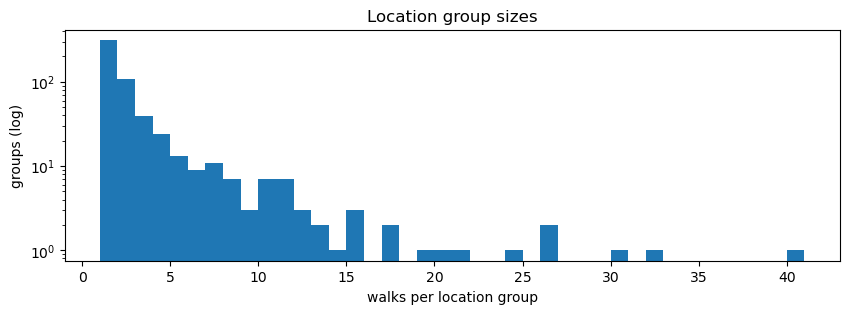

In [4]:
# Location groups: link two walks when any two of their camera positions are within LOCATION_RADIUS_M (3D);
# a group = walks connected through such links (union-find). A group is assigned to validation or train as a whole.
points = frames[["pos_x", "pos_y", "pos_z"]].to_numpy()
walk_of_point = frames["session"].map({session: number for number, session in enumerate(sessions)}).to_numpy()
parent = list(range(len(sessions)))


def find(walk):
    """Root of a walk's group (with path halving)."""
    while parent[walk] != walk:
        parent[walk] = parent[parent[walk]]
        walk = parent[walk]
    return walk


for first, second in cKDTree(points).query_pairs(LOCATION_RADIUS_M):
    a, b = walk_of_point[first], walk_of_point[second]
    if a != b:
        parent[find(a)] = find(b)
roots = [find(walk) for walk in range(len(sessions))]
group_ids = {root: number for number, root in enumerate(sorted(set(roots)))}
walks["group"] = [group_ids[root] for root in roots]
group_sizes = walks["group"].value_counts()
groups_with_both = sum(walks.loc[walks["group"] == g, "camera"].nunique() > 1 for g in group_sizes.index)
print(f"{len(group_sizes)} location groups (radius {LOCATION_RADIUS_M} m) | walks alone: {int((group_sizes == 1).sum())} | "
      f"largest group: {int(group_sizes.max())} walks ({group_sizes.max() / len(sessions):.1%}) | "
      f"groups with both cameras: {groups_with_both}")
figure, axis = plt.subplots(figsize=(10, 3))
axis.hist(group_sizes, bins=range(1, int(group_sizes.max()) + 2), log=True)
axis.set_xlabel("walks per location group"); axis.set_ylabel("groups (log)"); axis.set_title("Location group sizes")
plt.show()

## 4. One row per walk, per camera

In [5]:
cameras = ["chest", "head"]
camera_of_walk = walks["camera"].to_numpy()
walk_frames = walks["frames"].to_numpy()
walk_batch = walks["batch"].to_numpy()
walk_group = walks["group"].to_numpy()
per_walk = frames.groupby("session")
walk_class_pixels = per_walk[class_names].sum().reindex(sessions).to_numpy(dtype=np.float64)       # walks x classes
walk_class_frames = (frames[class_names] > 0).groupby(frames["session"]).sum().reindex(sessions).to_numpy()
batch_names = sorted(walks["batch"].unique())

required, max_walks_per_class, batch_target = {}, {}, {}
for camera in cameras:
    mine = camera_of_walk == camera
    class_walk_counts = (walk_class_pixels[mine] > 0).sum(axis=0)
    required[camera] = class_walk_counts >= REQUIRED_CLASS_MIN_WALK_SHARE * mine.sum()
    max_walks_per_class[camera] = np.floor(class_walk_counts * MAX_SHARE_OF_CLASS_WALKS)
    batch_target[camera] = {batch: VALIDATION_SHARE * int(((walk_batch == batch) & mine).sum())
                            for batch in batch_names if ((walk_batch == batch) & mine).any()}
    print(f"{camera}: {mine.sum()} walks | classes that must appear in validation: {int(required[camera].sum())} of "
          f"{len(class_names)} | target validation walks per batch folder: "
          + ", ".join(f"{batch.split('/')[0][:22]}.../{batch.split('/')[-1]} {target:.1f}"
                      for batch, target in batch_target[camera].items()))

chest: 773 walks | classes that must appear in validation: 18 of 29 | target validation walks per batch folder: Batch_2pt0_04_06_2023.../Chest 14.3, Batch_2pt1_04_06_2023.../Chest 4.4, Batch_3_5_18_2023.../batch_3_chest 40.8, PD_Goku_Batch_1_Hue_Tr.../High_FPS_Chest 1.6, PD_Goku_Batch_1_Hue_Tr.../Low_FPS_Chest 5.3, PD_Goku_Batch_1_Hue_Tr.../Med_FPS_Chest 1.3, PD_Goku_Batch_1pt1_2_2.../Zed_2 1.2, PD_Goku_Batch_1pt1_2_2.../Zed_2 4.9, PD_Goku_Batch_1pt1_2_2.../Zed_2 1.4, PD_Goku_Vehicle_Centri.../ 2.1
head: 787 walks | classes that must appear in validation: 18 of 29 | target validation walks per batch folder: Batch_2pt0_04_06_2023.../Head 14.5, Batch_2pt1_04_06_2023.../Head 5.1, Batch_3_5_18_2023.../batch_3_head 43.6, PD_Goku_Batch_1_Hue_Tr.../High_FPS_Head 1.4, PD_Goku_Batch_1_Hue_Tr.../Low_FPS_Head 5.5, PD_Goku_Batch_1_Hue_Tr.../Med_FPS_Head 1.2, PD_Goku_Batch_1pt1_2_2.../Zed_Mini 1.3, PD_Goku_Batch_1pt1_2_2.../Zed_Mini 5.1, PD_Goku_Batch_1pt1_2_2.../Zed_Mini 1.0


## 5. Choose the validation walks

Same scoring as the chest split, computed **per camera** and added up: class pixels (half the summed absolute
difference of the pixel shares), class frames (mean absolute difference of the share of frames containing each class),
batch mix (mean absolute difference of the share of walks from each batch folder), and size (distance from 10%). Each distance is divided by its median over random splits before adding.
A candidate is made by adding random location groups until both cameras reach 10% of their frames.

In [6]:
def camera_distances(is_validation, camera):
    """Distances between validation and train for one camera. Returns {name: float}."""
    mine = camera_of_walk == camera
    validation, train = is_validation & mine, ~is_validation & mine
    validation_frames, train_frames = walk_frames[validation].sum(), walk_frames[train].sum()
    validation_pixels, train_pixels = walk_class_pixels[validation].sum(axis=0), walk_class_pixels[train].sum(axis=0)
    batch_share = lambda part: np.array([(walk_batch[part] == batch).sum() for batch in batch_target[camera]]) / max(part.sum(), 1)
    return {
        "class pixels": 0.5 * np.abs(validation_pixels / validation_pixels.sum() - train_pixels / train_pixels.sum()).sum(),
        "class frames": np.abs(walk_class_frames[validation].sum(axis=0) / validation_frames
                               - walk_class_frames[train].sum(axis=0) / train_frames).mean(),
        "batches": np.abs(batch_share(validation) - batch_share(train)).mean(),
        "size": abs(validation_frames / walk_frames[mine].sum() - VALIDATION_SHARE),
    }


def split_distances(is_validation):
    """Both cameras' distances, named "<camera> <distance>". Returns {name: float}."""
    return {f"{camera} {name}": value for camera in cameras for name, value in camera_distances(is_validation, camera).items()}


def broken_rules(is_validation):
    """The rules a candidate breaks (empty list = all rules kept)."""
    broken = []
    for camera in cameras:
        mine = camera_of_walk == camera
        validation, train = is_validation & mine, ~is_validation & mine
        share = walk_frames[validation].sum() / walk_frames[mine].sum()
        if not FRAME_SHARE_RANGE[0] <= share <= FRAME_SHARE_RANGE[1]:
            broken.append(f"{camera}: validation holds {share:.1%} of the frames")
        for batch, target in batch_target[camera].items():
            count = int((walk_batch[validation] == batch).sum())
            if abs(count - target) > max(1.0, BATCH_WALK_TOLERANCE * target):
                broken.append(f"{camera}: {count} validation walks from {batch} (target {target:.1f})")
        validation_class_frames = walk_class_frames[validation].sum(axis=0)
        train_class_frames = walk_class_frames[train].sum(axis=0)
        validation_count, train_count = walk_frames[validation].sum(), walk_frames[train].sum()
        validation_class_walks = (walk_class_pixels[validation] > 0).sum(axis=0)
        for index, class_name in enumerate(class_names):
            validation_share = validation_class_frames[index] / max(validation_count, 1)
            train_share = train_class_frames[index] / max(train_count, 1)
            if required[camera][index]:
                if validation_class_frames[index] < MIN_FRAMES_IN_VALIDATION:
                    broken.append(f"{camera} {class_name}: only {validation_class_frames[index]} validation frames")
                if not MIN_RELATIVE_FRAME_SHARE * train_share <= validation_share <= MAX_RELATIVE_FRAME_SHARE * train_share:
                    broken.append(f"{camera} {class_name}: in {validation_share:.1%} of validation frames, "
                                  f"{train_share:.1%} in train")
            if validation_class_walks[index] > max_walks_per_class[camera][index]:
                broken.append(f"{camera} {class_name}: {validation_class_walks[index]} validation walks "
                              f"(max {int(max_walks_per_class[camera][index])})")
    return broken


group_members = [np.flatnonzero(walk_group == group) for group in range(walk_group.max() + 1)]
camera_totals = {camera: walk_frames[camera_of_walk == camera].sum() for camera in cameras}


# Per batch folder (each is one camera and one frame rate): the validation walks wanted (10% of its walks, rounded,
# at least 1) and the most allowed (the rule's upper bound). Location groups can hold walks of several batch folders.
batch_index = {batch: number for number, batch in enumerate(batch_names)}
walk_batch_number = np.array([batch_index[batch] for batch in walk_batch])
batch_walks = np.bincount(walk_batch_number, minlength=len(batch_names))
batch_wanted = np.maximum(1, np.round(VALIDATION_SHARE * batch_walks)).astype(int)
batch_most = np.floor(VALIDATION_SHARE * batch_walks + np.maximum(1.0, BATCH_WALK_TOLERANCE * VALIDATION_SHARE * batch_walks))
group_batch_counts = np.array([np.bincount(walk_batch_number[members], minlength=len(batch_names))
                               for members in group_members])          # location groups x batch folders


def random_candidate(generator):
    """Add location groups in random order; take a group only if it adds a walk to a batch folder that still wants
    one and pushes no batch folder above its upper bound. Stop when every batch folder has its wanted walks.
    Returns yes/no per walk. (The frame shares and the class rules are checked afterwards by broken_rules.)"""
    is_validation = np.zeros(len(sessions), dtype=bool)
    counts = np.zeros(len(batch_names), dtype=int)
    for group in generator.permutation(len(group_members)):
        added = group_batch_counts[group]
        if not (added[counts < batch_wanted] > 0).any():
            continue                                      # adds nothing to a batch folder that still wants walks
        if ((counts + added) > batch_most).any():
            continue                                      # would overfill a batch folder
        is_validation[group_members[group]] = True
        counts += added
        if (counts >= batch_wanted).all():
            break
    return is_validation

In [7]:
if FIXED_VALIDATION_WALKS is not None:
    is_chosen = np.isin(sessions, FIXED_VALIDATION_WALKS)
    print("Checking the fixed list:", broken_rules(is_chosen) or "all rules kept")
    candidates_kept = None
else:
    generator = np.random.default_rng(SEED)
    kept, kept_distances, reference = [], [], []
    start_time = time.time()
    for candidate in range(1, CANDIDATES + 1):
        # random_candidate takes: the random generator; returns: yes/no per walk (validation)
        is_validation = random_candidate(generator)
        if candidate <= NORMALIZATION_CANDIDATES:
            reference.append(split_distances(is_validation))
        if not broken_rules(is_validation):
            kept.append(is_validation)
            kept_distances.append(split_distances(is_validation))
        if candidate % 10000 == 0 or candidate == CANDIDATES:
            elapsed = time.time() - start_time
            print(f"[{candidate:,}/{CANDIDATES:,}] kept {len(kept):,} | elapsed {elapsed:.0f}s | "
                  f"ETA {elapsed / candidate * (CANDIDATES - candidate):.0f}s", flush=True)
    candidates_kept = len(kept)
    if not kept:
        raise RuntimeError("no candidate kept all rules: look at broken_rules(random_candidate(...)) and the settings")
    medians = pd.DataFrame(reference).median().replace(0, 1e-12)
    distances = pd.DataFrame(kept_distances)
    distances["total"] = (distances / medians).sum(axis=1)
    print(f"\n{candidates_kept:,} of {CANDIDATES:,} candidates kept all rules; best total "
          f"{distances['total'].min():.2f} (median {distances['total'].median():.2f})")
    display(distances.sort_values("total").head(5).round(4))

    def total_distance(is_validation):
        """Each distance divided by its median over random splits, added up."""
        return sum(value / medians[name] for name, value in split_distances(is_validation).items())

    # ---- Fast swaps. A swap moves one validation group to train and one train group to validation, so the new
    # validation totals are: current totals - that group's totals + the other group's totals. With every group's totals
    # computed once (frames, class pixels, class frames, walks with each class, walks per batch folder, per camera), all
    # train groups are tried against one validation group in a single numpy step: the SAME rules and distances as
    # broken_rules and split_distances, written on totals (checked against them below).
    camera_masks = [camera_of_walk == camera for camera in cameras]
    number_of_groups = len(group_members)
    group_frames = np.zeros((number_of_groups, len(cameras)))
    group_pixels = np.zeros((number_of_groups, len(cameras), len(class_names)))
    group_class_frames = np.zeros_like(group_pixels)
    group_class_walks = np.zeros_like(group_pixels)
    for group, members in enumerate(group_members):
        for c, mask in enumerate(camera_masks):
            mine = members[mask[members]]
            group_frames[group, c] = walk_frames[mine].sum()
            group_pixels[group, c] = walk_class_pixels[mine].sum(axis=0)
            group_class_frames[group, c] = walk_class_frames[mine].sum(axis=0)
            group_class_walks[group, c] = (walk_class_pixels[mine] > 0).sum(axis=0)
    group_batches = group_batch_counts.astype(float)                        # groups x batch folders (walk counts)
    total_frames = np.array([camera_totals[camera] for camera in cameras], dtype=float)
    total_pixels = group_pixels.sum(axis=0)
    total_class_frames = group_class_frames.sum(axis=0)
    total_batch_walks = group_batches.sum(axis=0)
    camera_of_batch = np.array([walks.loc[walks["batch"] == batch, "camera"].iloc[0] for batch in batch_names])
    batch_targets = VALIDATION_SHARE * total_batch_walks
    batch_tolerance = np.maximum(1.0, BATCH_WALK_TOLERANCE * batch_targets)
    required_matrix = np.array([required[camera] for camera in cameras])
    max_walks_matrix = np.array([max_walks_per_class[camera] for camera in cameras])
    median_of = {name: medians[name] for name in medians.index}

    def totals_of(is_validation):
        """Validation totals of a split: (frames, pixels, class frames, class walks, batch walks)."""
        members = sorted(set(walk_group[is_validation]))
        return (group_frames[members].sum(axis=0), group_pixels[members].sum(axis=0),
                group_class_frames[members].sum(axis=0), group_class_walks[members].sum(axis=0),
                group_batches[members].sum(axis=0))

    def score_totals(frames, pixels, class_frames, class_walks, batch_walks):
        """Total distance of many splits at once from their validation totals (leading axis = splits); np.inf where
        a split breaks a rule. Same rules and distances as broken_rules / split_distances."""
        with np.errstate(divide="ignore", invalid="ignore"):
            share = frames / total_frames                                            # splits x cameras
            ok = ((share >= FRAME_SHARE_RANGE[0]) & (share <= FRAME_SHARE_RANGE[1])).all(axis=1)
            ok &= (np.abs(batch_walks - batch_targets) <= batch_tolerance).all(axis=1)
            train_frames = total_frames - frames
            validation_share = class_frames / frames[..., None]
            train_share = (total_class_frames - class_frames) / train_frames[..., None]
            required_broken = required_matrix & ((class_frames < MIN_FRAMES_IN_VALIDATION)
                                                 | (validation_share < MIN_RELATIVE_FRAME_SHARE * train_share)
                                                 | (validation_share > MAX_RELATIVE_FRAME_SHARE * train_share))
            ok &= ~required_broken.any(axis=(1, 2))
            ok &= ~(class_walks > max_walks_matrix).any(axis=(1, 2))
            total = np.zeros(len(frames))
            for c, camera in enumerate(cameras):
                validation_pixels, train_pixels = pixels[:, c], total_pixels[c] - pixels[:, c]
                pixel_distance = 0.5 * np.abs(validation_pixels / validation_pixels.sum(axis=1, keepdims=True)
                                              - train_pixels / train_pixels.sum(axis=1, keepdims=True)).sum(axis=1)
                frame_distance = np.abs(validation_share[:, c] - (total_class_frames[c] - class_frames[:, c])
                                        / train_frames[:, c, None]).mean(axis=1)
                mine = camera_of_batch == camera
                validation_walks = batch_walks[:, mine].sum(axis=1, keepdims=True)
                train_walks = total_batch_walks[mine].sum() - validation_walks
                batch_distance = np.abs(batch_walks[:, mine] / validation_walks
                                        - (total_batch_walks[mine] - batch_walks[:, mine]) / train_walks).mean(axis=1)
                size_distance = np.abs(share[:, c] - VALIDATION_SHARE)
                total += (pixel_distance / median_of[f"{camera} class pixels"]
                          + frame_distance / median_of[f"{camera} class frames"]
                          + batch_distance / median_of[f"{camera} batches"]
                          + size_distance / median_of[f"{camera} size"])
        return np.where(ok & np.isfinite(total), total, np.inf)

    def improve_by_swaps(start, seed=None):
        """Each round: try EVERY (validation group, train group) swap (vectorized per validation group); keep the best
        one that lowers the total and keeps all rules; stop when no swap helps. Returns (split, total, swaps made)."""
        current = start.copy()
        current_groups = np.zeros(number_of_groups, dtype=bool)
        current_groups[sorted(set(walk_group[current]))] = True
        current_totals = totals_of(current)
        current_total = float(score_totals(*[value[None] for value in current_totals])[0])
        swaps = 0
        while True:
            train_groups = np.flatnonzero(~current_groups)
            best_swap, best_total = None, current_total
            for out_group in np.flatnonzero(current_groups):
                trial = [value - part[out_group] + part[train_groups]
                         for value, part in zip(current_totals, (group_frames, group_pixels, group_class_frames,
                                                                 group_class_walks, group_batches))]
                scores = score_totals(*trial)
                best_index = int(np.argmin(scores))
                if scores[best_index] < best_total - 1e-12:
                    best_swap, best_total = (out_group, int(train_groups[best_index])), float(scores[best_index])
            if best_swap is None:
                return current, current_total, swaps
            out_group, in_group = best_swap
            current_groups[out_group], current_groups[in_group] = False, True
            current[group_members[out_group]] = False
            current[group_members[in_group]] = True
            current_totals = totals_of(current)
            current_total, swaps = best_total, swaps + 1

    # check the fast scoring against the original rules and distances on a few kept candidates
    for candidate in kept[:20]:
        fast = float(score_totals(*[value[None] for value in totals_of(candidate)])[0])
        assert abs(fast - total_distance(candidate)) < 1e-6, (fast, total_distance(candidate))
    print("fast swap scoring = the original rules and distances (checked on 20 candidates)")

    best_result = None
    start_time = time.time()
    order = distances["total"].sort_values().index[:SWAP_STARTS]
    starts = [(int(candidate_index), kept[candidate_index], SEED + number) for number, candidate_index in enumerate(order)]

    def report(number, candidate_index, improved, improved_total, swaps):
        """Keep the best result so far and print one progress line."""
        global best_result
        if best_result is None or improved_total < best_result[1] - 1e-12:
            best_result = (improved, improved_total)
        print(f"  [{number}/{len(starts)} done] {distances.loc[candidate_index, 'total']:.3f} -> {improved_total:.3f} "
              f"after {swaps} swaps | best {best_result[1]:.3f} | elapsed {time.time() - start_time:.0f}s", flush=True)

    print(f"\nSwaps from the {len(starts)} best random candidates (every partner tried, fast scoring):", flush=True)
    for number, (candidate_index, start, seed) in enumerate(starts, start=1):
        # improve_by_swaps takes: a starting split; returns: (improved split, its total, swaps made)
        report(number, candidate_index, *improve_by_swaps(start))
    is_chosen = best_result[0]
chosen_walks = sorted(np.array(sessions)[is_chosen].tolist())
assert not broken_rules(is_chosen), broken_rules(is_chosen)
print(f"\nchosen: {len(chosen_walks)} validation walks in {len(set(walk_group[is_chosen]))} location groups")

[10,000/100,000] kept 1,902 | elapsed 25s | ETA 227s
[20,000/100,000] kept 3,802 | elapsed 50s | ETA 201s
[30,000/100,000] kept 5,819 | elapsed 67s | ETA 157s
[40,000/100,000] kept 7,724 | elapsed 84s | ETA 126s
[50,000/100,000] kept 9,679 | elapsed 100s | ETA 100s
[60,000/100,000] kept 11,708 | elapsed 117s | ETA 78s
[70,000/100,000] kept 13,632 | elapsed 134s | ETA 57s
[80,000/100,000] kept 15,527 | elapsed 151s | ETA 38s
[90,000/100,000] kept 17,451 | elapsed 170s | ETA 19s
[100,000/100,000] kept 19,352 | elapsed 186s | ETA 0s

19,352 of 100,000 candidates kept all rules; best total 4.38 (median 7.41)


,chest class pixels,chest class frames,chest batches,chest size,head class pixels,head class frames,head batches,head size,total
10000,0.0326,0.0114,0.0063,0.0007,0.0176,0.0156,0.0050,0.0062,4.3819
14385,0.0292,0.0126,0.0078,0.0018,0.0216,0.0131,0.0068,0.0058,4.6773
5759,0.0185,0.0119,0.0130,0.0061,0.0198,0.0133,0.0068,0.0003,4.7723
11296,0.0272,0.0103,0.0052,0.0072,0.0324,0.0106,0.0079,0.0063,4.7823
5979,0.0124,0.0109,0.0076,0.0061,0.0184,0.0122,0.0087,0.0151,4.7831


fast swap scoring = the original rules and distances (checked on 20 candidates)

Swaps from the 10 best random candidates (every partner tried, fast scoring):
  [1/10 done] 4.382 -> 2.022 after 22 swaps | best 2.022 | elapsed 1s
  [2/10 done] 4.677 -> 1.778 after 36 swaps | best 1.778 | elapsed 3s
  [3/10 done] 4.772 -> 1.751 after 24 swaps | best 1.751 | elapsed 4s
  [4/10 done] 4.782 -> 2.201 after 21 swaps | best 1.751 | elapsed 5s
  [5/10 done] 4.783 -> 1.655 after 26 swaps | best 1.655 | elapsed 6s
  [6/10 done] 4.795 -> 2.046 after 29 swaps | best 1.655 | elapsed 7s
  [7/10 done] 4.805 -> 1.835 after 25 swaps | best 1.655 | elapsed 9s
  [8/10 done] 4.812 -> 2.610 after 28 swaps | best 1.655 | elapsed 10s
  [9/10 done] 4.812 -> 1.710 after 37 swaps | best 1.655 | elapsed 12s
  [10/10 done] 4.859 -> 1.841 after 29 swaps | best 1.655 | elapsed 14s

chosen: 155 validation walks in 65 location groups


### Save the chosen walks

In [8]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "validation_walks.txt").write_text("\n".join(chosen_walks) + "\n")
record = {
    "validation_walks": chosen_walks,
    "per_camera": {camera: {"validation_walks": int((is_chosen & (camera_of_walk == camera)).sum()),
                            "validation_frames": int(walk_frames[is_chosen & (camera_of_walk == camera)].sum()),
                            "train_frames": int(walk_frames[~is_chosen & (camera_of_walk == camera)].sum())}
                   for camera in cameras},
    "location_groups_in_validation": int(len(set(walk_group[is_chosen]))),
    "distances": {name: round(float(value), 5) for name, value in split_distances(is_chosen).items()},
    "candidates_tried": None if FIXED_VALIDATION_WALKS is not None else CANDIDATES,
    "candidates_kept": candidates_kept,
    "settings": {"VALIDATION_SHARE": VALIDATION_SHARE, "FRAME_SHARE_RANGE": FRAME_SHARE_RANGE,
                 "BATCH_WALK_TOLERANCE": BATCH_WALK_TOLERANCE,
                 "REQUIRED_CLASS_MIN_WALK_SHARE": REQUIRED_CLASS_MIN_WALK_SHARE,
                 "MIN_FRAMES_IN_VALIDATION": MIN_FRAMES_IN_VALIDATION, "MIN_RELATIVE_FRAME_SHARE": MIN_RELATIVE_FRAME_SHARE,
                 "MAX_RELATIVE_FRAME_SHARE": MAX_RELATIVE_FRAME_SHARE, "MAX_SHARE_OF_CLASS_WALKS": MAX_SHARE_OF_CLASS_WALKS,
                 "IGNORED_CLASSES": IGNORED_CLASSES, "LOCATION_RADIUS_M": LOCATION_RADIUS_M, "CANDIDATES": CANDIDATES,
                 "NORMALIZATION_CANDIDATES": NORMALIZATION_CANDIDATES, "SWAP_STARTS": SWAP_STARTS,
                 "SEED": SEED,
                 "FIXED_VALIDATION_WALKS": FIXED_VALIDATION_WALKS},
}
(RESULTS_DIR / "validation_split.json").write_text(json.dumps(record, indent=2))
print("saved", RESULTS_DIR / "validation_walks.txt", "and", RESULTS_DIR / "validation_split.json")

saved D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\synthetic\validation_split\results\validation_walks.txt and D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\synthetic\validation_split\results\validation_split.json


## 6. Comparison: size and render batches

In [9]:
rows = []
for camera in cameras:
    for batch in list(batch_target[camera]) + ["all"]:
        mine = (camera_of_walk == camera) & ((walk_batch == batch) if batch != "all" else True)
        rows.append({"camera": camera, "batch folder": batch,
                     "validation walks": int((is_chosen & mine).sum()), "train walks": int((~is_chosen & mine).sum()),
                     "validation frames": int(walk_frames[is_chosen & mine].sum()),
                     "train frames": int(walk_frames[~is_chosen & mine].sum())})
size_table = pd.DataFrame(rows).set_index(["camera", "batch folder"])
size_table["validation share of frames %"] = (100 * size_table["validation frames"]
                                              / (size_table["validation frames"] + size_table["train frames"])).round(1)
display(size_table)

validation walks  train walks  validation frames  train frames  validation share of frames %
camera batch folder                                                                                                                                    
chest  Batch_2pt0_04_06_2023/Chest                                       15          128                750          6400                          10.5
       Batch_2pt1_04_06_2023/Chest                                        5           39                250          1950                          11.4
       Batch_3_5_18_2023/batch_3_chest                                   41          367               2050         18350                          10.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/High_...                 2           14                334          2338                          12.5
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Low_F...                 5           48                250          2400                           9.4
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Med_F...                 1           12                143          1716                           7.7
       PD_Goku_Batch_1pt1_2_2_2023/High_FPS/Zed_2                         1           11                167          1837                           8.3
       PD_Goku_Batch_1pt1_2_2_2023/Low_FPS/Zed_2                          5           44                250          2200                          10.2
       PD_Goku_Batch_1pt1_2_2_2023/Medium_FPS/Zed_2                       1           13                143          1859                           7.1
       PD_Goku_Vehicle_Centric_Samples/                                   2           19                286          2717                           9.5
       all                                                               78          695               4623         41767                          10.0
head   Batch_2pt0_04_06_2023/Head                                        14          131                700          6550                           9.7
       Batch_2pt1_04_06_2023/Head                                         5           46                250          2300                           9.8
       Batch_3_5_18_2023/batch_3_head                                    43          393               2150         19650                           9.9
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/High_...                 2           12                334          2004                          14.3
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Low_F...                 5           50                250          2500                           9.1
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Med_F...                 1           11                143          1573                           8.3
       PD_Goku_Batch_1pt1_2_2_2023/High_FPS/Zed_Mini                      1           12                167          2004                           7.7
       PD_Goku_Batch_1pt1_2_2_2023/Low_FPS/Zed_Mini                       5           46                250          2300                           9.8
       PD_Goku_Batch_1pt1_2_2_2023/Medium_FPS/Zed_Mini                    1            9                143          1287                          10.0
       all                                                               77          710               4387         40168                           9.8

## 7. Comparison: classes (per camera)


chest: classes present in its synthetic walks


,train pixel %,validation pixel %,train frames %,validation frames %,must appear
building,37.260,37.245,99.995,100.000,True
sidewalk,17.687,17.699,99.603,99.027,True
sky,11.542,11.537,94.048,94.506,True
road,10.520,10.623,97.757,96.626,True
pedestrian,7.084,6.991,83.080,82.868,True
tree,5.317,5.294,90.674,89.660,True
terrain,2.478,2.476,86.386,86.481,True
vehicle,2.453,2.530,84.847,84.880,True
obstacle,1.537,1.567,94.534,93.727,True
pole,1.161,1.017,95.537,92.645,True



head: classes present in its synthetic walks


,train pixel %,validation pixel %,train frames %,validation frames %,must appear
building,39.179,39.331,99.990,100.000,True
sidewalk,18.723,18.885,99.788,99.840,True
sky,12.133,12.132,95.571,97.219,True
road,11.697,11.686,98.648,98.678,True
tree,5.121,5.087,97.137,97.675,True
terrain,2.986,3.048,93.338,96.034,True
pedestrian,2.693,2.697,85.887,86.095,True
vehicle,2.119,2.111,88.317,87.623,True
obstacle,1.416,1.415,96.896,96.877,True
vegetation,1.169,1.093,31.137,30.932,True


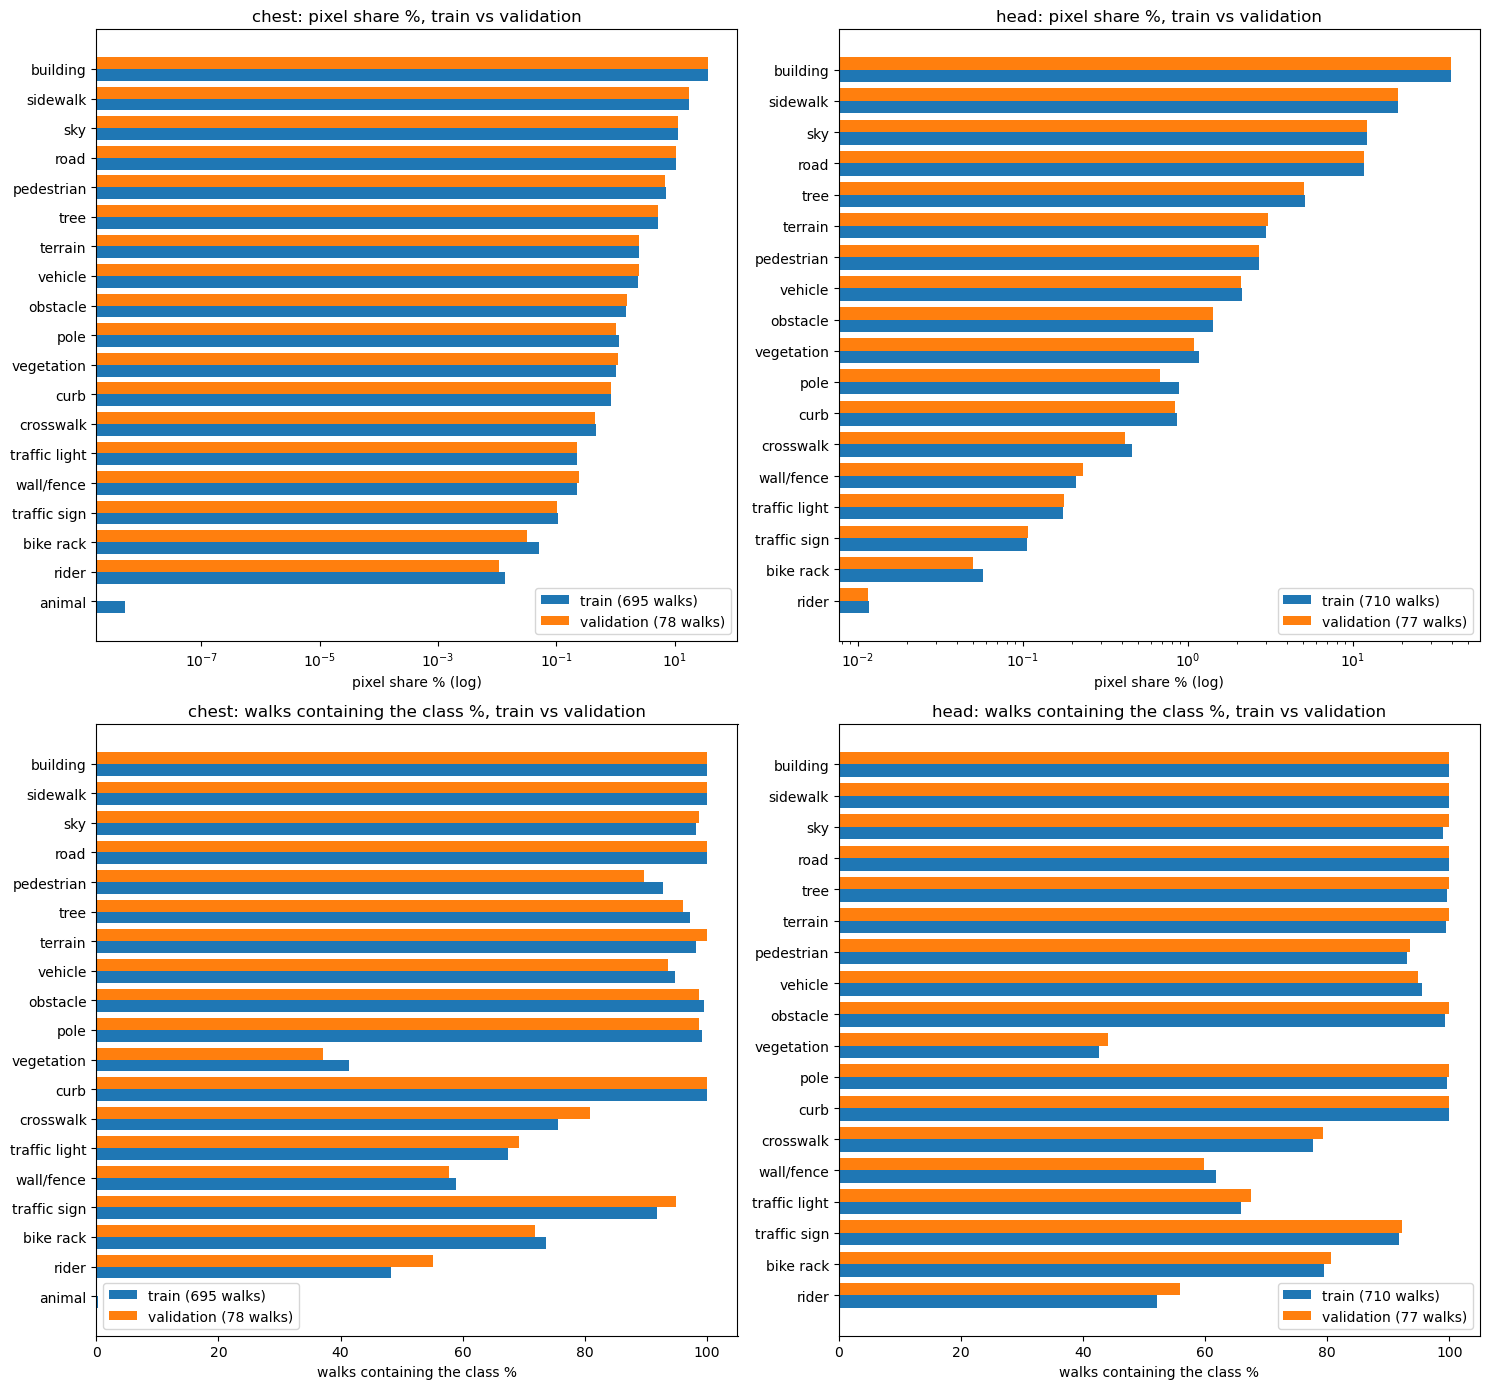

In [14]:
for camera in cameras:
    mine = camera_of_walk == camera
    validation, train = is_chosen & mine, ~is_chosen & mine
    table = pd.DataFrame({
        "train pixel %": 100 * walk_class_pixels[train].sum(axis=0) / walk_class_pixels[train].sum(),
        "validation pixel %": 100 * walk_class_pixels[validation].sum(axis=0) / walk_class_pixels[validation].sum(),
        "train frames %": 100 * walk_class_frames[train].sum(axis=0) / walk_frames[train].sum(),
        "validation frames %": 100 * walk_class_frames[validation].sum(axis=0) / walk_frames[validation].sum(),
        "must appear": required[camera]}, index=class_names).round(3)
    table = table[(table["train pixel %"] > 0) | (table["validation pixel %"] > 0)]
    print(f"\n{camera}: classes present in its synthetic walks")
    display(table.sort_values("train pixel %", ascending=False))

# Plots: per camera, train vs validation: (top) class pixel share, (bottom) share of walks that contain the class
figure, axes = plt.subplots(2, len(cameras), figsize=(15, 14), squeeze=False)
for column, camera in enumerate(cameras):
    mine = camera_of_walk == camera
    validation, train = is_chosen & mine, ~is_chosen & mine
    measures = {
        "pixel share %": (100 * walk_class_pixels[train].sum(axis=0) / walk_class_pixels[train].sum(),
                          100 * walk_class_pixels[validation].sum(axis=0) / walk_class_pixels[validation].sum()),
        "walks containing the class %": (100 * (walk_class_pixels[train] > 0).mean(axis=0),
                                         100 * (walk_class_pixels[validation] > 0).mean(axis=0)),
    }
    present = np.flatnonzero((measures["pixel share %"][0] > 0) | (measures["pixel share %"][1] > 0))
    order = present[np.argsort(measures["pixel share %"][0][present])]     # same class order in both plots
    y = np.arange(len(order))
    for row, (name, (train_values, validation_values)) in enumerate(measures.items()):
        axis = axes[row, column]
        axis.barh(y - 0.2, train_values[order], height=0.4, label=f"train ({int(train.sum())} walks)")
        axis.barh(y + 0.2, validation_values[order], height=0.4, label=f"validation ({int(validation.sum())} walks)")
        axis.set_yticks(y, [class_names[i] for i in order])
        if name == "pixel share %":
            axis.set_xscale("log")
        axis.set_xlabel(name + (" (log)" if name == "pixel share %" else ""))
        axis.set_title(f"{camera}: {name}, train vs validation"); axis.legend()
plt.tight_layout(); plt.show()

## 8. Check: no validation walk retraces a train walk's spot

In [11]:
validation_points = points[is_chosen[walk_of_point]]
train_points = points[~is_chosen[walk_of_point]]
# cKDTree.query takes: points; returns: (distance to the nearest train position, its index) for each validation position
nearest, _ = cKDTree(train_points).query(validation_points)
print(f"closest distance between any validation position and any train position: {nearest.min():.2f} m "
      f"(must be > {LOCATION_RADIUS_M} m) | median {np.median(nearest):.1f} m")
assert nearest.min() > LOCATION_RADIUS_M

closest distance between any validation position and any train position: 5.37 m (must be > 5.0 m) | median 13.8 m


## 9. Summary

Fill in after running: validation walks and frames per camera, batch mix, classes, the location check. Then run
`../prepare_sanpo_synthetic_modal.py` again on each session: it skips every finished walk and only rewrites the lists,
now with `val.txt` and `data.yaml`.

## 10. Summary of the chosen split

In [13]:
print("=" * 78)
print("SANPO-Synthetic validation split: summary")
print("=" * 78)
totals = {"validation walks": 0, "train walks": 0, "validation frames": 0, "train frames": 0}
for camera in cameras:
    mine = camera_of_walk == camera
    numbers = {"validation walks": int((is_chosen & mine).sum()), "train walks": int((~is_chosen & mine).sum()),
               "validation frames": int(walk_frames[is_chosen & mine].sum()),
               "train frames": int(walk_frames[~is_chosen & mine].sum())}
    for key, value in numbers.items():
        totals[key] += value
    share = numbers["validation frames"] / (numbers["validation frames"] + numbers["train frames"])
    print(f"{camera:<6}: validation {numbers['validation walks']} of {int(mine.sum())} walks "
          f"({numbers['validation walks'] / mine.sum():.1%}) | {numbers['validation frames']:,} of "
          f"{numbers['validation frames'] + numbers['train frames']:,} frames ({share:.1%}) | train "
          f"{numbers['train walks']} walks, {numbers['train frames']:,} frames")
print(f"both  : validation {totals['validation walks']} of {len(sessions)} walks | {totals['validation frames']:,} of "
      f"{totals['validation frames'] + totals['train frames']:,} frames "
      f"({totals['validation frames'] / (totals['validation frames'] + totals['train frames']):.1%})")
print(f"\nlocation groups (radius {LOCATION_RADIUS_M} m): {len(group_members)} in total, "
      f"{len(set(walk_group[is_chosen]))} in validation | closest validation-to-train position {nearest.min():.2f} m "
      f"(median {np.median(nearest):.1f} m)")
print(f"rules: {'all kept' if not broken_rules(is_chosen) else broken_rules(is_chosen)} | candidates kept "
      f"{candidates_kept:,} of {CANDIDATES:,} | swap starts {SWAP_STARTS}")
print(f"total distance of the chosen split: {total_distance(is_chosen):.3f} (best random candidate "
      f"{distances['total'].min():.3f}, median candidate {distances['total'].median():.3f})")
print("distances (validation vs train):")
for name, value in split_distances(is_chosen).items():
    print(f"   {name:<20} {value:.4f}")
print("\nvalidation walks per batch folder (target about 10%):")
display(size_table[["validation walks", "train walks", "validation frames", "train frames",
                    "validation share of frames %"]])
print(f"saved: {RESULTS_DIR / 'validation_walks.txt'} ({len(chosen_walks)} walks) and "
      f"{RESULTS_DIR / 'validation_split.json'}")

SANPO-Synthetic validation split: summary
chest : validation 78 of 773 walks (10.1%) | 4,623 of 46,390 frames (10.0%) | train 695 walks, 41,767 frames
head  : validation 77 of 787 walks (9.8%) | 4,387 of 44,555 frames (9.8%) | train 710 walks, 40,168 frames
both  : validation 155 of 1560 walks | 9,010 of 90,945 frames (9.9%)

location groups (radius 5.0 m): 560 in total, 65 in validation | closest validation-to-train position 5.37 m (median 13.8 m)
rules: all kept | candidates kept 19,352 of 100,000 | swap starts 10
total distance of the chosen split: 1.655 (best random candidate 4.382, median candidate 7.406)
distances (validation vs train):
   chest class pixels   0.0034
   chest class frames   0.0063
   chest batches        0.0045
   chest size           0.0003
   head class pixels    0.0041
   head class frames    0.0041
   head batches         0.0032
   head size            0.0015

validation walks per batch folder (target about 10%):


validation walks  train walks  validation frames  train frames  validation share of frames %
camera batch folder                                                                                                                                    
chest  Batch_2pt0_04_06_2023/Chest                                       15          128                750          6400                          10.5
       Batch_2pt1_04_06_2023/Chest                                        5           39                250          1950                          11.4
       Batch_3_5_18_2023/batch_3_chest                                   41          367               2050         18350                          10.0
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/High_...                 2           14                334          2338                          12.5
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Low_F...                 5           48                250          2400                           9.4
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Med_F...                 1           12                143          1716                           7.7
       PD_Goku_Batch_1pt1_2_2_2023/High_FPS/Zed_2                         1           11                167          1837                           8.3
       PD_Goku_Batch_1pt1_2_2_2023/Low_FPS/Zed_2                          5           44                250          2200                          10.2
       PD_Goku_Batch_1pt1_2_2_2023/Medium_FPS/Zed_2                       1           13                143          1859                           7.1
       PD_Goku_Vehicle_Centric_Samples/                                   2           19                286          2717                           9.5
       all                                                               78          695               4623         41767                          10.0
head   Batch_2pt0_04_06_2023/Head                                        14          131                700          6550                           9.7
       Batch_2pt1_04_06_2023/Head                                         5           46                250          2300                           9.8
       Batch_3_5_18_2023/batch_3_head                                    43          393               2150         19650                           9.9
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/High_...                 2           12                334          2004                          14.3
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Low_F...                 5           50                250          2500                           9.1
       PD_Goku_Batch_1_Hue_Transformed_1_23_2023/Med_F...                 1           11                143          1573                           8.3
       PD_Goku_Batch_1pt1_2_2_2023/High_FPS/Zed_Mini                      1           12                167          2004                           7.7
       PD_Goku_Batch_1pt1_2_2_2023/Low_FPS/Zed_Mini                       5           46                250          2300                           9.8
       PD_Goku_Batch_1pt1_2_2_2023/Medium_FPS/Zed_Mini                    1            9                143          1287                          10.0
       all                                                               77          710               4387         40168                           9.8

saved: D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\synthetic\validation_split\results\validation_walks.txt (155 walks) and D:\My Projects\blind-guide\fast_path\object_detection\data_code\sanpo\synthetic\validation_split\results\validation_split.json
